Processed 500/5000 parameter samples.
Processed 1000/5000 parameter samples.
Processed 1500/5000 parameter samples.
Processed 2000/5000 parameter samples.
Processed 2500/5000 parameter samples.
Processed 3000/5000 parameter samples.
Processed 3500/5000 parameter samples.
Processed 4000/5000 parameter samples.
Processed 4500/5000 parameter samples.
Processed 5000/5000 parameter samples.
Trainable block type: product
Number of trainable parameters: 24
Non-Haar prior width: 0.35
Fixed query hyperparameter: [0.785398163397 1.047197551197]
Query layer weights: [1, 2]
x modes per coordinate: [-2, -1, 0, 1, 2]
query modes per coordinate: [-3, -2, -1, 0, 1, 2, 3]
query-spectrum check (occupied modes, invariant across alpha, out-of-support weight):  {'local': (49, True, '6.695e-17'), 'nonlocal': (49, True, '9.877e-17')}
query-gate operator nonseparable weight (local path max, nonlocal endpoint min): 0.000e+00, 0.359835
maximum fixed-parameter shape change:  {'local': 0.9996580168611807, 'local_

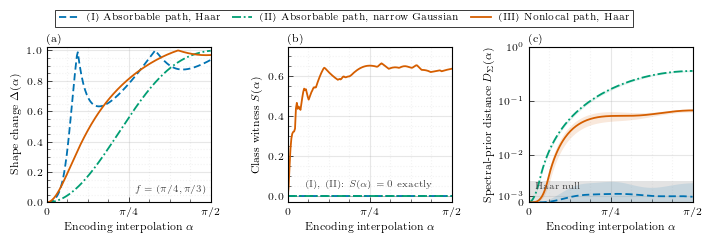

In [1]:
"""Encoding-conditioned inductive bias in a two-qubit reuploading circuit.

The circuit is a genuine data-reuploading ansatz in which the data vector
x and the query vector f are encoded in alternating layers, each layer
encoding one component per qubit:

    U(x, f; theta, alpha)
        = prod_{l=1}^{L} V_l E_f^(l)(f; alpha) W_l E_x(x),

    E_x(x)            = RZ_0(x_0) RZ_1(x_1),
    E_f^(l)(f; alpha) = exp[-i s_l f_1 G_1(alpha)/2]
                        exp[-i s_l f_0 G_0(alpha)/2].

Qubit q carries component q of both vectors, so the x layer and the f
layer have the same shape and the query is not concatenated into unused
encoding slots. The layer weights s_l = (1, 2) are common to both qubits.
The query value f is a fixed hyperparameter, not an input: only the query
encoding is varied, through the interpolation angle alpha.

Each query generator is a spectrum-preserving interpolation out of the
local Pauli X_q,

    local path      G_q(alpha) = cos(alpha) X_q + sin(alpha) Y_q,
    nonlocal path   G_0(alpha) = cos(alpha) X_0 + sin(alpha) Y_0 Z_1,
                    G_1(alpha) = cos(alpha) X_1 + sin(alpha) Z_0 Y_1.

The two Pauli terms of every generator anticommute, so G_q(alpha)^2 = I
for all alpha and both paths. The generator eigenvalues are therefore
+-1 throughout, each layer contributes query frequencies {-s_l, 0, s_l}
to coordinate q, and the joint query spectrum is contained in
{-3,...,3}^2 independently of alpha and of the path. Only the
eigenspaces, and their coupling to the rest of the circuit, change.

The nonlocal targets are a swap-covariant pair rather than a common ZZ.
A common ZZ would make G_0(pi/2) = G_1(pi/2), collapsing the query gate
to R_ZZ(s_l (f_0 + f_1)); the function would then depend on f_0 + f_1
alone and the joint query spectrum would shrink to its diagonal at the
endpoint. The pair keeps the two query coordinates acting through
distinct generators at every alpha, so the joint query spectrum is
invariant along the whole path. validate_query_spectrum() checks this
numerically rather than relying on the argument.

Combining the two paths with two parameter priors gives one series for
each case of the functional trichotomy, with alpha in place of the query
value as the abscissa:

  "local"        Absorbable local encoding, Haar trainable blocks. The
                 query gate is a product of single-qubit unitaries for
                 every alpha and is absorbed into the adjacent product
                 block, so H(alpha) = H(alpha'). Right invariance of Haar
                 then also gives P(alpha) = P(alpha'). Case I, and the
                 sampling null that calibrates panel (c).

  "local_narrow" Same absorbable encoding, but Euler angles drawn from
                 untruncated zero-mean Gaussians. The support, and hence
                 the reachable set and the hypothesis class, is unchanged,
                 so absorption still gives H(alpha) = H(alpha'). Right
                 invariance is lost, so Sigma(alpha) != Sigma(alpha').
                 Case II.

  "nonlocal"     Interpolation towards the nonlocal generator pair with
                 Haar trainable blocks. At alpha = 0 the encoding is a
                 product and the circuit is a product, so every function
                 in H(0) is separable in (x_0, x_1); at alpha > 0 the
                 query gate is no longer a product unitary and
                 nonseparable functions appear. Case III.

The figure reads as a two-bit classifier. Panel (a) is the naive test and
separates nothing. Panel (b) is the class bit and panel (c) is the prior
bit:

                      (b) class     (c) prior
      I   inert           0             0
      II  reweighting     0           nonzero
      III class change  nonzero       nonzero

The class bit is the maximum nonseparable weight

    S(alpha) = max_theta [ 1 - sigma_1^2 / sum_i sigma_i^2 ]

of the x-coefficient matrix A(theta, alpha). Every function in H(0) is
separable whenever the trainable blocks are products and the query gate
is a product unitary, so S(alpha) > 0 exhibits a function at alpha that
is not in H(0). Because S is a maximum, sampling can only under-report
it, which is the right direction for an existence claim; a mean over
theta would be a prior-weighted quantity and therefore the wrong object
for a statement about the class. For the absorbable paths with product
blocks the state stays a product state, so the floor of S is exactly zero
rather than a sampling floor.

Absorbability is itself certified numerically: a query gate is absorbable
into product trainable blocks exactly when it is a product unitary, which
is the vanishing of its operator-Schmidt nonseparable weight.

The default trainable blocks are products of independently sampled
single-qubit SU(2) unitaries. Set TRAINABLE_BLOCKS=cnot to append a fixed
CNOT to every local trainable block as a robustness check; the absorption
argument survives that change, but separability no longer certifies
anything, and panel (b) correctly reports this by lifting for all series.

The width of the non-Haar prior is controlled by

    NARROW_SIGMA=0.35

and the fixed query hyperparameter by

    FIXED_QUERY_VECTOR=0.7853981633974483,1.0471975511965976
"""

import os

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D


# =====================================================================
# Configuration
# =====================================================================

NUMBER_OF_QUBITS = 2
NUMBER_OF_LAYERS = 2

# Layer weights s_l of the query encoding, shared by both qubits.
QUERY_WEIGHTS = np.array([1, 2], dtype=int)

# Four SU(2) x SU(2) blocks: W_l,V_l for l=1,2. Each block contains
# two three-angle Euler parameterizations, giving 4 x 2 x 3 = 24 angles.
NUMBER_OF_TRAINABLE_BLOCKS = 2 * NUMBER_OF_LAYERS
PARAMETERS_PER_BLOCK = 6
NUMBER_OF_PARAMETERS = (
    NUMBER_OF_TRAINABLE_BLOCKS * PARAMETERS_PER_BLOCK
)

GRID_SIZE = int(os.environ.get("GRID_SIZE", "8"))
QUERY_GRID_SIZE = int(os.environ.get("QUERY_GRID_SIZE", "16"))
NUMBER_OF_ENCODING_POINTS = int(
    os.environ.get("N_ENCODING_POINTS", "181")
)
NUMBER_OF_ENSEMBLE_SAMPLES = int(
    os.environ.get("N_ENSEMBLE", "5000")
)
NUMBER_OF_SCHMIDT_SAMPLES = int(
    os.environ.get("N_SCHMIDT", "1000")
)
NUMBER_OF_JACKKNIFE_BLOCKS = int(
    os.environ.get("N_JACKKNIFE_BLOCKS", "10")
)

# Standard deviation of the non-Haar Euler-angle prior, in radians.
NARROW_SIGMA = float(os.environ.get("NARROW_SIGMA", "0.35"))

# The fixed query hyperparameter f = (f_0, f_1), one component per qubit.
# Generic values keep every single-qubit query rotation nontrivial and
# keep the nonlocal endpoint entangling.
DEFAULT_QUERY_VECTOR = (np.pi / 4.0, np.pi / 3.0)
FIXED_QUERY_VECTOR = np.asarray(
    [
        float(component)
        for component in os.environ.get(
            "FIXED_QUERY_VECTOR",
            ",".join(repr(float(value)) for value in DEFAULT_QUERY_VECTOR),
        ).split(",")
    ],
    dtype=float,
)

TRAINABLE_BLOCKS = os.environ.get(
    "TRAINABLE_BLOCKS", "product"
).lower()
if TRAINABLE_BLOCKS not in {"product", "cnot"}:
    raise ValueError(
        "TRAINABLE_BLOCKS must be either 'product' or 'cnot'."
    )

def latex_is_usable():
    """
    Report whether matplotlib's usetex backend can actually run here.

    A machine can have a latex binary on PATH while lacking the base
    format and macros that usetex needs. Probing once at import time
    avoids losing a completed ensemble to a rendering failure in the
    final savefig call.
    """
    import shutil
    import subprocess

    if shutil.which("latex") is None or shutil.which("dvipng") is None:
        return False
    try:
        completed = subprocess.run(
            ["kpsewhich", "latex.ltx"],
            capture_output=True,
            timeout=30,
            check=False,
        )
    except (OSError, subprocess.SubprocessError):
        return False
    return completed.returncode == 0 and bool(completed.stdout.strip())


# USE_TEX=1 requests the usetex backend, USE_TEX=0 forces mathtext.
# A request is honoured only if the local installation can serve it;
# otherwise the figure falls back to mathtext with the Computer Modern
# font set, which is visually close and always available.
USE_TEX_REQUESTED = os.environ.get("USE_TEX", "1") == "1"
USE_TEX = USE_TEX_REQUESTED and latex_is_usable()
FIXED_PARAMETER_SEED = 5
NARROW_FIXED_PARAMETER_SEED = 7
ENSEMBLE_SEED = 1234
NARROW_ENSEMBLE_SEED = 4321
SPECTRUM_CHECK_SEED = 99
NUMBER_OF_SPECTRUM_CHECK_SAMPLES = 4
ZERO_TOLERANCE = 1e-14
# A query-Fourier mode counts as occupied above this magnitude. The
# populated modes sit at 1e-3 and above and the vanishing ones at 1e-17,
# so the classification is insensitive to the exact threshold.
SPECTRUM_OCCUPATION_TOLERANCE = 1e-10

# Each series is a pair (encoding path, parameter distribution).
SERIES = ("local", "local_narrow", "nonlocal")
PATH_OF_SERIES = {
    "local": "local",
    "local_narrow": "local",
    "nonlocal": "nonlocal",
}
DISTRIBUTION_OF_SERIES = {
    "local": "haar",
    "local_narrow": "narrow",
    "nonlocal": "haar",
}
ABSORBABLE_SERIES = ("local", "local_narrow")
NULL_SERIES = "local"

if GRID_SIZE < 5:
    raise ValueError(
        "GRID_SIZE must be at least 5 to resolve x modes -2,...,2."
    )
if NUMBER_OF_ENCODING_POINTS < 2:
    raise ValueError("N_ENCODING_POINTS must be at least 2.")
if NUMBER_OF_ENSEMBLE_SAMPLES < 2:
    raise ValueError("N_ENSEMBLE must be at least 2.")
if FIXED_QUERY_VECTOR.shape != (NUMBER_OF_QUBITS,):
    raise ValueError(
        "FIXED_QUERY_VECTOR must have one component per qubit."
    )
if np.any(np.isclose(np.sin(FIXED_QUERY_VECTOR), 0.0, atol=1e-12)):
    raise ValueError(
        "No component of FIXED_QUERY_VECTOR may be an integer multiple "
        "of pi; such values make the corresponding query rotation "
        "trivial at the interpolation endpoints."
    )


# =====================================================================
# Operators and elementary gates
# =====================================================================

I2 = np.eye(2, dtype=complex)
X = np.array([[0.0, 1.0], [1.0, 0.0]], dtype=complex)
Y = np.array([[0.0, -1.0j], [1.0j, 0.0]], dtype=complex)
Z = np.diag([1.0, -1.0]).astype(complex)


def kron(*operators):
    """Kronecker product of an arbitrary number of operators."""
    result = np.array([[1.0 + 0.0j]])
    for operator in operators:
        result = np.kron(result, operator)
    return result


I4 = np.eye(4, dtype=complex)
X0 = kron(X, I2)
X1 = kron(I2, X)
Y0 = kron(Y, I2)
Y1 = kron(I2, Y)
Z0 = kron(Z, I2)
Z1 = kron(I2, Z)
ZZ = Z0 @ Z1

# Local generator of the query encoding on each qubit, and the two
# spectrum-preserving targets it is rotated into.
LOCAL_GENERATORS = (X0, X1)
ROTATED_LOCAL_GENERATORS = (Y0, Y1)
NONLOCAL_GENERATORS = (Y0 @ Z1, Z0 @ Y1)

CNOT_01 = np.array(
    [
        [1.0, 0.0, 0.0, 0.0],
        [0.0, 1.0, 0.0, 0.0],
        [0.0, 0.0, 0.0, 1.0],
        [0.0, 0.0, 1.0, 0.0],
    ],
    dtype=complex,
)


def pauli_rotation(pauli, angle):
    r"""Return exp(-i angle pauli / 2) for a Hermitian involution."""
    identity = np.eye(pauli.shape[0], dtype=complex)
    if not np.allclose(pauli @ pauli, identity, atol=1e-12):
        raise ValueError("The supplied generator does not square to identity.")
    return (
        np.cos(angle / 2.0) * identity
        - 1j * np.sin(angle / 2.0) * pauli
    )


def single_qubit_su2(euler_angles):
    r"""Euler parameterization RZ(alpha) RY(beta) RZ(gamma)."""
    alpha, beta, gamma = euler_angles
    return (
        pauli_rotation(Z, alpha)
        @ pauli_rotation(Y, beta)
        @ pauli_rotation(Z, gamma)
    )


def sample_haar_euler_parameters(rng):
    r"""Sample ZYZ Euler angles from Haar measure on SU(2)."""
    alpha = rng.uniform(0.0, 2.0 * np.pi)
    gamma = rng.uniform(0.0, 2.0 * np.pi)
    beta = np.arccos(rng.uniform(-1.0, 1.0))
    return np.array([alpha, beta, gamma])


def sample_narrow_euler_parameters(rng):
    r"""
    Sample ZYZ Euler angles from zero-mean Gaussians of width NARROW_SIGMA.

    The Gaussians are untruncated, so the angles have full support on R^3
    and the induced measure on SU(2) has full support even though it is
    strongly concentrated near the identity. The hypothesis class is
    therefore unchanged relative to the Haar case, while the induced
    distribution over unitaries is far from Haar and in particular is not
    right invariant.
    """
    return rng.normal(0.0, NARROW_SIGMA, size=3)


PARAMETER_SAMPLERS = {
    "haar": sample_haar_euler_parameters,
    "narrow": sample_narrow_euler_parameters,
}


def sample_parameters(rng, distribution="haar"):
    """Sample all 24 Euler-angle parameters of the circuit."""
    sampler = PARAMETER_SAMPLERS[distribution]
    parameters = np.empty(
        (NUMBER_OF_TRAINABLE_BLOCKS, NUMBER_OF_QUBITS, 3), dtype=float
    )
    for block in range(NUMBER_OF_TRAINABLE_BLOCKS):
        for qubit in range(NUMBER_OF_QUBITS):
            parameters[block, qubit] = sampler(rng)
    return parameters


def trainable_block(block_parameters, block_type):
    r"""Construct U^(0) tensor U^(1), optionally followed by CNOT."""
    local = kron(
        single_qubit_su2(block_parameters[0]),
        single_qubit_su2(block_parameters[1]),
    )
    if block_type == "product":
        return local
    if block_type == "cnot":
        return CNOT_01 @ local
    raise ValueError("Unknown trainable block type.")


def data_encoding(x):
    r"""E_x(x) = RZ(x_0) tensor RZ(x_1), one component per qubit."""
    return pauli_rotation(Z0, x[0]) @ pauli_rotation(Z1, x[1])


def query_generator(encoding_angle, qubit, path):
    r"""Return the spectrum-preserving generator G_q(alpha)."""
    local_generator = LOCAL_GENERATORS[qubit]
    if path == "local":
        second_generator = ROTATED_LOCAL_GENERATORS[qubit]
    elif path == "nonlocal":
        second_generator = NONLOCAL_GENERATORS[qubit]
    else:
        raise ValueError("path must be either 'local' or 'nonlocal'.")

    generator = (
        np.cos(encoding_angle) * local_generator
        + np.sin(encoding_angle) * second_generator
    )
    if not np.allclose(generator @ generator, I4, atol=1e-12):
        raise RuntimeError(
            "The interpolated query generator does not square to identity."
        )
    return generator


def query_encoding(query_vector, encoding_angle, layer, path):
    r"""
    Return E_f^(l)(f; alpha), the query layer of the reuploading circuit.

    Qubit q is rotated by s_l f_q about its own generator G_q(alpha). The
    factors are applied in the fixed order q = 0 then q = 1; on the local
    path they commute, on the nonlocal path the order is a convention of
    the ansatz.
    """
    weight = QUERY_WEIGHTS[layer]
    gate = I4
    for qubit in range(NUMBER_OF_QUBITS):
        gate = (
            pauli_rotation(
                query_generator(encoding_angle, qubit, path),
                weight * query_vector[qubit],
            )
            @ gate
        )
    return gate


def operator_nonseparable_weight(gate):
    r"""
    Operator-Schmidt nonseparable weight of a two-qubit gate.

    Zero exactly for a product unitary A tensor B, which is exactly the
    condition under which the gate is absorbed into product trainable
    blocks. Positive values certify that no such absorption exists.
    """
    reshuffled = (
        gate.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(4, 4)
    )
    singular_values = np.linalg.svd(reshuffled, compute_uv=False)
    weights = singular_values**2
    return float(1.0 - weights[0] / np.sum(weights))


# =====================================================================
# Fourier grids and spectrum-preserving encoding paths
# =====================================================================

PLUS = np.array([1.0, 1.0], dtype=complex) / np.sqrt(2.0)
INITIAL_STATE = kron(PLUS, PLUS).reshape(-1)

ENCODING_ANGLES = np.linspace(
    0.0, np.pi / 2.0, NUMBER_OF_ENCODING_POINTS
)

SCALAR_GRID = 2.0 * np.pi * np.arange(GRID_SIZE) / GRID_SIZE
DATA_ENCODINGS = np.asarray([
    data_encoding(np.array([x0, x1]))
    for x0 in SCALAR_GRID
    for x1 in SCALAR_GRID
])

QUERY_ENCODINGS = {
    path: np.asarray([
        [
            query_encoding(
                FIXED_QUERY_VECTOR, encoding_angle, layer, path
            )
            for layer in range(NUMBER_OF_LAYERS)
        ]
        for encoding_angle in ENCODING_ANGLES
    ])
    for path in ("local", "nonlocal")
}

FULL_MODES = np.fft.fftshift(
    np.fft.fftfreq(GRID_SIZE, d=1.0 / GRID_SIZE)
).astype(int)
X_MODE_INDICES = np.flatnonzero(
    np.abs(FULL_MODES) <= NUMBER_OF_LAYERS
)
X_MODES = FULL_MODES[X_MODE_INDICES]


def accessible_query_modes():
    """
    Minkowski sum of the layerwise difference spectra of one coordinate.

    Every layer contributes exp(-i s_l f_q G_q/2) with G_q^2 = I, hence
    generator eigenvalues +-1 and layer frequencies {-s_l, 0, s_l} in
    coordinate q, for every alpha and both paths.
    """
    modes = {0}
    for weight in QUERY_WEIGHTS:
        layer_modes = {-int(weight), 0, int(weight)}
        modes = {left + right for left in modes for right in layer_modes}
    return np.asarray(sorted(modes), dtype=int)


QUERY_MODES = accessible_query_modes()

QUERY_SCALAR_GRID = (
    2.0 * np.pi * np.arange(QUERY_GRID_SIZE) / QUERY_GRID_SIZE
)
QUERY_FULL_MODES = np.fft.fftshift(
    np.fft.fftfreq(QUERY_GRID_SIZE, d=1.0 / QUERY_GRID_SIZE)
).astype(int)
SPECTRUM_CHECK_ANGLES = np.array(
    [0.0, np.pi / 8.0, np.pi / 4.0, 3.0 * np.pi / 8.0, np.pi / 2.0]
)
# A generic data point; the query spectrum must not depend on it.
SPECTRUM_CHECK_DATA_POINT = np.array([0.37, 1.13])

if QUERY_GRID_SIZE <= 2 * int(np.max(QUERY_MODES)):
    raise ValueError(
        "QUERY_GRID_SIZE must exceed twice the largest query mode so "
        "that the spectrum check can detect out-of-support content."
    )


def query_spectrum_coefficients(
    parameters,
    path,
    encoding_angle,
    data_point=SPECTRUM_CHECK_DATA_POINT,
    block_type=TRAINABLE_BLOCKS,
):
    r"""
    Return the joint query-Fourier coefficients C[omega_f0, omega_f1].

    The data vector and the parameters are held fixed and the circuit is
    evaluated on a QUERY_GRID_SIZE^2 grid in (f_0, f_1). This is the
    object whose support must be invariant along the encoding paths.
    """
    blocks = [
        trainable_block(parameters[index], block_type)
        for index in range(NUMBER_OF_TRAINABLE_BLOCKS)
    ]
    encoding = data_encoding(data_point)

    query_gates = np.asarray([
        [
            query_encoding(
                np.array([f0, f1]), encoding_angle, layer, path
            )
            for f0 in QUERY_SCALAR_GRID
            for f1 in QUERY_SCALAR_GRID
        ]
        for layer in range(NUMBER_OF_LAYERS)
    ])

    number_of_query_points = QUERY_GRID_SIZE**2
    states = np.broadcast_to(
        INITIAL_STATE,
        (number_of_query_points, INITIAL_STATE.size),
    ).copy()

    for layer in range(NUMBER_OF_LAYERS):
        W_layer = blocks[2 * layer]
        V_layer = blocks[1 + 2 * layer]
        states = np.einsum("ij,fj->fi", encoding, states, optimize=True)
        states = np.einsum("ij,fj->fi", W_layer, states, optimize=True)
        states = np.einsum(
            "fij,fj->fi", query_gates[layer], states, optimize=True
        )
        states = np.einsum("ij,fj->fi", V_layer, states, optimize=True)

    expectations = np.einsum(
        "fi,ij,fj->f", states.conj(), ZZ, states, optimize=True
    )
    values = expectations.real.reshape(QUERY_GRID_SIZE, QUERY_GRID_SIZE)
    return np.fft.fftshift(
        np.fft.fft2(values) / QUERY_GRID_SIZE**2
    )


def validate_query_spectrum(block_type=TRAINABLE_BLOCKS):
    r"""
    Verify that the joint query spectrum is invariant along both paths.

    The claim to be checked is that the query spectrum does not change
    along a path, so the test is support identity, not support size. At
    each sampled alpha the occupied mode set is collected as a maximum
    over parameter samples and compared to the set at alpha = 0. Two
    properties are asserted per path: containment, no Fourier weight
    outside the predicted {-3,...,3}^2, and invariance, the occupied set
    is the same at every alpha as at alpha = 0.

    Support size is reported but not asserted, because it legitimately
    depends on the trainable blocks: product blocks populate all 49
    modes, while a fixed CNOT in every block cancels some of them. What
    must not depend on alpha is which modes are occupied.
    """
    inside = np.abs(QUERY_FULL_MODES) <= int(np.max(QUERY_MODES))
    inside_mask = np.outer(inside, inside)
    mode_grid = np.stack(
        np.meshgrid(QUERY_FULL_MODES, QUERY_FULL_MODES, indexing="ij"),
        axis=-1,
    )
    rng = np.random.default_rng(SPECTRUM_CHECK_SEED)
    parameter_samples = [
        sample_parameters(rng, "haar")
        for _ in range(NUMBER_OF_SPECTRUM_CHECK_SAMPLES)
    ]

    report = {}
    for path in ("local", "nonlocal"):
        leakage = 0.0
        support_sets = {}
        for encoding_angle in SPECTRUM_CHECK_ANGLES:
            magnitudes = np.zeros_like(inside_mask, dtype=float)
            for parameters in parameter_samples:
                coefficients = query_spectrum_coefficients(
                    parameters, path, encoding_angle, block_type=block_type
                )
                np.maximum(
                    magnitudes, np.abs(coefficients), out=magnitudes
                )
            leakage = max(
                leakage, float(np.max(magnitudes[~inside_mask]))
            )
            occupied = magnitudes > SPECTRUM_OCCUPATION_TOLERANCE
            support_sets[float(encoding_angle)] = frozenset(
                map(tuple, mode_grid[occupied].tolist())
            )

        if leakage > 1e-10:
            raise RuntimeError(
                f"The {path} path leaks query-Fourier weight outside the "
                f"predicted support (max {leakage:.3e})."
            )

        reference_support = support_sets[float(SPECTRUM_CHECK_ANGLES[0])]
        changed_angles = [
            angle
            for angle, support in support_sets.items()
            if support != reference_support
        ]
        invariant = not changed_angles
        if not invariant:
            largest_difference = max(
                len(support_sets[angle] ^ reference_support)
                for angle in changed_angles
            )
            message = (
                f"The query spectrum of the {path} path changes along the "
                f"encoding interpolation with TRAINABLE_BLOCKS="
                f"{block_type}: the occupied mode set differs from its "
                f"alpha=0 value at {len(changed_angles)} of "
                f"{len(support_sets)} sampled angles, by up to "
                f"{largest_difference} modes."
            )
            if block_type == "product":
                raise RuntimeError(message)
            # The CNOT variant is a robustness check, not the figure.
            # Its spectrum is not invariant and the run continues with
            # that stated explicitly rather than silently.
            print(f"Warning: {message}")

        report[path] = {
            "out_of_support_weight": leakage,
            "support_size": len(reference_support),
            "support_invariant": invariant,
        }
    return report


def validate_encoding_paths():
    """Verify Hermiticity, spectrum, endpoints, and absorbability."""
    target_spectrum = np.array([-1.0, -1.0, 1.0, 1.0])
    for path in ("local", "nonlocal"):
        for encoding_angle in ENCODING_ANGLES:
            for qubit in range(NUMBER_OF_QUBITS):
                generator = query_generator(encoding_angle, qubit, path)
                if not np.allclose(
                    generator, generator.conj().T, atol=1e-12
                ):
                    raise RuntimeError(
                        "A query generator is not Hermitian."
                    )
                eigenvalues = np.linalg.eigvalsh(generator)
                if not np.allclose(
                    eigenvalues, target_spectrum, atol=1e-12
                ):
                    raise RuntimeError(
                        "The query-generator spectrum changes along a path."
                    )

        # Both paths start at the same local encoding.
        for qubit in range(NUMBER_OF_QUBITS):
            if not np.allclose(
                query_generator(0.0, qubit, path),
                LOCAL_GENERATORS[qubit],
                atol=1e-12,
            ):
                raise RuntimeError(
                    "An alpha=0 generator is not the local Pauli."
                )

    for qubit in range(NUMBER_OF_QUBITS):
        if not np.allclose(
            query_generator(np.pi / 2.0, qubit, "local"),
            ROTATED_LOCAL_GENERATORS[qubit],
            atol=1e-12,
        ):
            raise RuntimeError(
                "The local-path endpoint is not the rotated local Pauli."
            )
        if not np.allclose(
            query_generator(np.pi / 2.0, qubit, "nonlocal"),
            NONLOCAL_GENERATORS[qubit],
            atol=1e-12,
        ):
            raise RuntimeError(
                "The nonlocal-path endpoint is not the nonlocal target."
            )

    # The nonlocal targets must stay distinct, otherwise the query gate
    # degenerates into a single two-qubit rotation and the joint query
    # spectrum collapses onto its diagonal at the endpoint.
    if np.allclose(
        NONLOCAL_GENERATORS[0], NONLOCAL_GENERATORS[1], atol=1e-12
    ):
        raise RuntimeError(
            "The nonlocal query generators coincide, which would make "
            "the query gate depend on f_0 + f_1 alone."
        )

    # Absorbability. The local path stays a product unitary for every
    # alpha, which is what lets it be absorbed into the product blocks;
    # the nonlocal path leaves that set as soon as alpha > 0.
    local_defect = 0.0
    nonlocal_defect_at_zero = 0.0
    for encoding_angle in ENCODING_ANGLES:
        for layer in range(NUMBER_OF_LAYERS):
            local_defect = max(
                local_defect,
                operator_nonseparable_weight(
                    query_encoding(
                        FIXED_QUERY_VECTOR, encoding_angle, layer, "local"
                    )
                ),
            )
    for layer in range(NUMBER_OF_LAYERS):
        nonlocal_defect_at_zero = max(
            nonlocal_defect_at_zero,
            operator_nonseparable_weight(
                query_encoding(FIXED_QUERY_VECTOR, 0.0, layer, "nonlocal")
            ),
        )
    if local_defect > 1e-12:
        raise RuntimeError(
            "A local-path query gate is not a product unitary "
            f"(nonseparable weight {local_defect:.3e})."
        )
    if nonlocal_defect_at_zero > 1e-12:
        raise RuntimeError(
            "The alpha=0 nonlocal query gate is not a product unitary."
        )
    nonlocal_defect_at_end = min(
        operator_nonseparable_weight(
            query_encoding(
                FIXED_QUERY_VECTOR, np.pi / 2.0, layer, "nonlocal"
            )
        )
        for layer in range(NUMBER_OF_LAYERS)
    )
    if nonlocal_defect_at_end < 1e-3:
        raise RuntimeError(
            "The nonlocal-path endpoint is still a product unitary."
        )

    if not np.array_equal(QUERY_MODES, np.arange(-3, 4)):
        raise RuntimeError("Unexpected common query-frequency support.")

    return {
        "local_operator_nonseparable_weight": local_defect,
        "nonlocal_endpoint_nonseparable_weight": nonlocal_defect_at_end,
    }


# =====================================================================
# Coefficient matrices over (x_0,x_1)
# =====================================================================

def coefficient_matrices(parameters, path, block_type=TRAINABLE_BLOCKS):
    r"""Return A_alpha[omega_x0,omega_x1] for every encoding angle."""
    blocks = [
        trainable_block(parameters[index], block_type)
        for index in range(NUMBER_OF_TRAINABLE_BLOCKS)
    ]

    number_of_grid_points = GRID_SIZE**2
    states = np.broadcast_to(
        INITIAL_STATE,
        (
            NUMBER_OF_ENCODING_POINTS,
            number_of_grid_points,
            INITIAL_STATE.size,
        ),
    ).copy()

    for layer in range(NUMBER_OF_LAYERS):
        W_layer = blocks[2 * layer]
        V_layer = blocks[1 + 2 * layer]

        states = np.einsum(
            "xij,axj->axi", DATA_ENCODINGS, states, optimize=True
        )
        states = np.einsum(
            "ij,axj->axi", W_layer, states, optimize=True
        )
        states = np.einsum(
            "aij,axj->axi",
            QUERY_ENCODINGS[path][:, layer],
            states,
            optimize=True,
        )
        states = np.einsum(
            "ij,axj->axi", V_layer, states, optimize=True
        )

    expectations = np.einsum(
        "axi,ij,axj->ax", states.conj(), ZZ, states, optimize=True
    )
    maximum_imaginary_part = np.max(np.abs(expectations.imag))
    if maximum_imaginary_part > 1e-10:
        raise RuntimeError(
            "Expectation values have unexpectedly large imaginary parts: "
            f"{maximum_imaginary_part:.3e}."
        )

    values = expectations.real.reshape(
        NUMBER_OF_ENCODING_POINTS, GRID_SIZE, GRID_SIZE
    )
    full_coefficients = np.fft.fftshift(
        np.fft.fft2(values, axes=(1, 2)) / GRID_SIZE**2,
        axes=(1, 2),
    )
    return full_coefficients[:, X_MODE_INDICES][:, :, X_MODE_INDICES]


# =====================================================================
# Diagnostics
# =====================================================================

def fixed_parameter_shape_change(coefficient_path):
    r"""Coefficient-direction change relative to alpha=0."""
    vectors = coefficient_path.reshape(NUMBER_OF_ENCODING_POINTS, -1)
    reference = vectors[0]
    norms = np.linalg.norm(vectors, axis=1)
    reference_norm = np.linalg.norm(reference)
    if reference_norm <= ZERO_TOLERANCE or np.any(norms <= ZERO_TOLERANCE):
        raise RuntimeError("Encountered a zero Fourier coefficient vector.")

    overlaps = np.einsum(
        "ai,i->a", vectors.conj(), reference, optimize=True
    )
    similarities = np.abs(overlaps) / (norms * reference_norm)
    changes = 1.0 - np.clip(similarities, 0.0, 1.0)
    changes[np.abs(changes) < 1e-12] = 0.0
    return changes


def normalized_matrix_distance(matrix, reference):
    r"""One minus the normalized real Frobenius alignment."""
    denominator = np.linalg.norm(matrix) * np.linalg.norm(reference)
    if denominator <= ZERO_TOLERANCE:
        raise RuntimeError("Cannot normalize a zero second-moment matrix.")
    alignment = np.vdot(matrix, reference).real / denominator
    return 1.0 - np.clip(alignment, 0.0, 1.0)


def separability_measures(coefficient_path):
    r"""
    Return the nonseparable weight and the entropy effective Schmidt rank.

    Both follow from the same singular values of A(theta, alpha). The
    nonseparable weight 1 - sigma_1^2 / sum_i sigma_i^2 vanishes exactly
    for a rank-one, that is coordinate-separable, coefficient matrix.
    """
    singular_values = np.linalg.svd(
        coefficient_path, compute_uv=False
    )
    weights = singular_values**2
    totals = np.sum(weights, axis=1, keepdims=True)
    if np.any(totals <= ZERO_TOLERANCE):
        raise RuntimeError("Encountered a zero coefficient matrix.")

    probabilities = weights / totals
    nonseparable = 1.0 - probabilities[:, 0]

    positive = probabilities > ZERO_TOLERANCE
    safe_probabilities = np.where(positive, probabilities, 1.0)
    entropies = -np.sum(
        np.where(
            positive,
            probabilities * np.log(safe_probabilities),
            0.0,
        ),
        axis=1,
    )
    return nonseparable, np.exp(entropies)


def jackknife_prior_statistics(total_moments, block_moments, block_sizes):
    r"""Bias-corrected prior distance from alpha=0 and its standard error."""
    number_of_samples = int(np.sum(block_sizes))
    number_of_blocks = len(block_sizes)
    prior_matrices = total_moments / number_of_samples
    reference = prior_matrices[0]

    raw_distances = np.asarray([
        normalized_matrix_distance(matrix, reference)
        for matrix in prior_matrices
    ])
    corrected_distances = np.empty_like(raw_distances)
    standard_errors = np.empty_like(raw_distances)

    for alpha_index in range(NUMBER_OF_ENCODING_POINTS):
        leave_one_out = []
        for block_index, block_size in enumerate(block_sizes):
            retained = number_of_samples - int(block_size)
            sigma_loo = (
                total_moments[alpha_index]
                - block_moments[block_index, alpha_index]
            ) / retained
            reference_loo = (
                total_moments[0]
                - block_moments[block_index, 0]
            ) / retained
            leave_one_out.append(
                normalized_matrix_distance(sigma_loo, reference_loo)
            )

        leave_one_out = np.asarray(leave_one_out)
        jackknife_mean = np.mean(leave_one_out)
        corrected = (
            number_of_blocks * raw_distances[alpha_index]
            - (number_of_blocks - 1) * jackknife_mean
        )
        corrected_distances[alpha_index] = max(0.0, corrected)
        standard_errors[alpha_index] = np.sqrt(
            (number_of_blocks - 1)
            / number_of_blocks
            * np.sum((leave_one_out - jackknife_mean) ** 2)
        )

    corrected_distances[0] = 0.0
    standard_errors[0] = 0.0
    return corrected_distances, standard_errors, raw_distances, prior_matrices


def ensemble_statistics():
    r"""
    Accumulate spectral moments and separability statistics per series.

    Nothing is stored per sample: the second moments are accumulated in
    place, and the class witness is a running maximum over the sampled
    parameters.
    """
    number_of_x_coefficients = len(X_MODES) ** 2
    number_of_blocks = min(
        NUMBER_OF_JACKKNIFE_BLOCKS, NUMBER_OF_ENSEMBLE_SAMPLES
    )
    sample_blocks = np.array_split(
        np.arange(NUMBER_OF_ENSEMBLE_SAMPLES), number_of_blocks
    )
    block_assignment = np.empty(NUMBER_OF_ENSEMBLE_SAMPLES, dtype=int)
    block_sizes = np.empty(number_of_blocks, dtype=int)
    for block_index, indices in enumerate(sample_blocks):
        block_assignment[indices] = block_index
        block_sizes[block_index] = len(indices)

    moment_shape = (
        NUMBER_OF_ENCODING_POINTS,
        number_of_x_coefficients,
        number_of_x_coefficients,
    )
    total_moments = {
        series: np.zeros(moment_shape, dtype=complex)
        for series in SERIES
    }
    block_moments = {
        series: np.zeros(
            (number_of_blocks,) + moment_shape, dtype=complex
        )
        for series in SERIES
    }

    number_of_schmidt_samples = min(
        NUMBER_OF_SCHMIDT_SAMPLES, NUMBER_OF_ENSEMBLE_SAMPLES
    )
    maximum_nonseparable = {
        series: np.zeros(NUMBER_OF_ENCODING_POINTS)
        for series in SERIES
    }
    nonseparable_sum = {
        series: np.zeros(NUMBER_OF_ENCODING_POINTS)
        for series in SERIES
    }
    schmidt_sum = {
        series: np.zeros(NUMBER_OF_ENCODING_POINTS)
        for series in SERIES
    }

    rngs = {
        "haar": np.random.default_rng(ENSEMBLE_SEED),
        "narrow": np.random.default_rng(NARROW_ENSEMBLE_SEED),
    }
    progress_interval = max(1, NUMBER_OF_ENSEMBLE_SAMPLES // 10)

    for sample_index in range(NUMBER_OF_ENSEMBLE_SAMPLES):
        parameters = {
            distribution: sample_parameters(rng, distribution)
            for distribution, rng in rngs.items()
        }

        for series in SERIES:
            coefficient_path = coefficient_matrices(
                parameters[DISTRIBUTION_OF_SERIES[series]],
                PATH_OF_SERIES[series],
            )
            vectors = coefficient_path.reshape(
                NUMBER_OF_ENCODING_POINTS, number_of_x_coefficients
            )

            # Outer products a a^dagger, matching the definition of Sigma.
            moments = np.einsum(
                "ai,aj->aij", vectors, vectors.conj(), optimize=True
            )
            total_moments[series] += moments
            block_moments[series][block_assignment[sample_index]] += moments

            if sample_index < number_of_schmidt_samples:
                nonseparable, ranks = separability_measures(
                    coefficient_path
                )
                np.maximum(
                    maximum_nonseparable[series],
                    nonseparable,
                    out=maximum_nonseparable[series],
                )
                nonseparable_sum[series] += nonseparable
                schmidt_sum[series] += ranks

        completed = sample_index + 1
        if (
            completed % progress_interval == 0
            or completed == NUMBER_OF_ENSEMBLE_SAMPLES
        ):
            print(
                f"Processed {completed}/{NUMBER_OF_ENSEMBLE_SAMPLES} "
                "parameter samples."
            )

    statistics = {}
    for series in SERIES:
        (
            prior_distance,
            prior_distance_error,
            prior_distance_raw,
            prior_matrices,
        ) = jackknife_prior_statistics(
            total_moments[series], block_moments[series], block_sizes
        )
        statistics[series] = {
            "prior_distance": prior_distance,
            "prior_distance_error": prior_distance_error,
            "prior_distance_raw": prior_distance_raw,
            "prior_matrices": prior_matrices,
            "nonseparable_weight": maximum_nonseparable[series],
            "mean_nonseparable_weight": (
                nonseparable_sum[series] / number_of_schmidt_samples
            ),
            "mean_schmidt_rank": (
                schmidt_sum[series] / number_of_schmidt_samples
            ),
        }
    return statistics


# =====================================================================
# Plot
# =====================================================================

COLOR = {
    "local": "#0072B2",
    "local_narrow": "#009E73",
    "nonlocal": "#D55E00",
}
STYLE = {
    "local": (0, (4, 2)),
    "local_narrow": (0, (5, 1.5, 1, 1.5)),
    "nonlocal": "-",
}
LABEL = {
    "local": r"(I) Absorbable path, Haar",
    "local_narrow": r"(II) Absorbable path, narrow Gaussian",
    "nonlocal": r"(III) Nonlocal path, Haar",
}
BAND_ALPHA = {"local": 0.12, "local_narrow": 0.13, "nonlocal": 0.14}
LEGEND_ORDER = ("local", "local_narrow", "nonlocal")


def configure_matplotlib():
    """Apply compact two-column paper styling."""
    mpl.rcParams.update(
        {
            "text.usetex": USE_TEX,
            "text.latex.preamble": r"\usepackage{amsmath}\usepackage{bm}",
            "font.family": "serif",
            "font.serif": ["Computer Modern Roman", "DejaVu Serif"],
            "mathtext.fontset": "cm",
            "font.size": 8,
            "axes.labelsize": 8,
            "axes.titlesize": 8,
            "axes.linewidth": 0.6,
            "axes.spines.top": True,
            "axes.spines.right": True,
            "xtick.labelsize": 7.5,
            "ytick.labelsize": 7.5,
            "xtick.major.width": 0.5,
            "ytick.major.width": 0.5,
            "xtick.minor.width": 0.4,
            "ytick.minor.width": 0.4,
            "xtick.direction": "in",
            "ytick.direction": "in",
            "legend.fontsize": 6.9,
            "legend.handlelength": 2.1,
            "legend.columnspacing": 1.2,
            "lines.linewidth": 1.3,
            "savefig.bbox": None,
        }
    )


def configure_encoding_axis(axis):
    axis.set_xlim(0.0, np.pi / 2.0)
    axis.set_xticks([0.0, np.pi / 4.0, np.pi / 2.0])
    axis.set_xticklabels([r"$0$", r"$\pi/4$", r"$\pi/2$"])
    axis.set_xlabel(r"Encoding interpolation $\alpha$")


def plot_series(axis, values, errors=None):
    """Draw every series, with an optional 95 percent band."""
    upper = -np.inf
    for series in SERIES:
        axis.plot(
            ENCODING_ANGLES,
            values[series],
            color=COLOR[series],
            ls=STYLE[series],
        )
        if errors is None:
            upper = max(upper, np.max(values[series]))
            continue

        half_width = 1.96 * errors[series]
        axis.fill_between(
            ENCODING_ANGLES,
            np.maximum(0.0, values[series] - half_width),
            values[series] + half_width,
            color=COLOR[series],
            alpha=BAND_ALPHA[series],
            linewidth=0,
        )
        upper = max(upper, np.max(values[series] + half_width))
    return upper


def query_vector_label():
    """A LaTeX label for the fixed query hyperparameter."""
    named = {
        np.pi / 2.0: r"\pi/2",
        np.pi / 3.0: r"\pi/3",
        np.pi / 4.0: r"\pi/4",
        np.pi / 6.0: r"\pi/6",
    }
    components = []
    for value in FIXED_QUERY_VECTOR:
        for reference, text in named.items():
            if np.isclose(value, reference):
                components.append(text)
                break
        else:
            components.append(f"{value:.3f}")
    return r"$f=(" + ",".join(components) + r")$"


def plot_figure(shape_change, statistics, noise_ceiling):
    configure_matplotlib()
    fig, axes = plt.subplots(1, 3, figsize=(7.08, 2.50))

    handles = [
        Line2D(
            [], [],
            color=COLOR[series],
            ls=STYLE[series],
            label=LABEL[series],
        )
        for series in LEGEND_ORDER
    ]
    legend = fig.legend(
        handles=handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.995),
        ncol=3,
        frameon=True,
        framealpha=0.9,
        edgecolor="black",
        fancybox=False,
    )
    legend.get_frame().set_linewidth(0.6)

    prior_distance = {
        series: statistics[series]["prior_distance"]
        for series in SERIES
    }
    prior_distance_error = {
        series: statistics[series]["prior_distance_error"]
        for series in SERIES
    }
    nonseparable_weight = {
        series: statistics[series]["nonseparable_weight"]
        for series in SERIES
    }

    # (a) Naive test: coefficient direction at one fixed parameter vector
    ax = axes[0]
    plot_series(ax, shape_change)
    configure_encoding_axis(ax)
    ax.set_ylim(0.0, 1.02)
    ax.set_ylabel(r"Shape change $\Delta(\alpha)$")
    ax.set_title("(a)", loc="left", pad=4, fontweight="bold")
    ax.annotate(
        query_vector_label(),
        xy=(0.97, 0.05),
        xycoords="axes fraction",
        ha="right",
        va="bottom",
        fontsize=7,
        color="0.25",
    )

    # (b) Class bit: existence of a nonseparable function at angle alpha
    ax = axes[1]
    upper_weight = plot_series(ax, nonseparable_weight)
    configure_encoding_axis(ax)
    ax.set_ylim(-0.045 * upper_weight, 1.12 * upper_weight)
    ax.axhline(0.0, color="0.55", linewidth=0.5, zorder=0)
    ax.set_ylabel(r"Class witness $S(\alpha)$")
    ax.set_title("(b)", loc="left", pad=4, fontweight="bold")
    if TRAINABLE_BLOCKS == "product":
        ax.annotate(
            r"(I), (II): $S(\alpha)=0$ exactly",
            xy=(np.pi / 4.0, 0.0),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=6.6,
            color="0.25",
        )

    # (c) Prior bit: change in the parameter-induced spectral second moment
    ax = axes[2]
    upper_distance = plot_series(
        ax, prior_distance, prior_distance_error
    )
    configure_encoding_axis(ax)
    ax.axhspan(
        0.0,
        noise_ceiling,
        color="0.80",
        alpha=0.55,
        linewidth=0,
        zorder=0,
    )
    # Linear inside the sampling null, logarithmic above it, so that the
    # nonzero values are all legible and areas cannot be read as
    # magnitudes.
    ax.set_yscale("symlog", linthresh=noise_ceiling, linscale=0.35)
    ax.set_ylim(0.0, max(1.0, 1.6 * upper_distance))
    ax.annotate(
        "Haar null",
        xy=(0.04 * np.pi / 2.0, noise_ceiling),
        xytext=(0, -1),
        textcoords="offset points",
        ha="left",
        va="top",
        fontsize=6.6,
        color="0.25",
    )
    ax.set_ylabel(r"Spectral-prior distance $D_{\Sigma}(\alpha)$")
    ax.set_title("(c)", loc="left", pad=4, fontweight="bold")

    for ax in axes:
        ax.set_axisbelow(True)
        ax.minorticks_on()
        ax.tick_params(which="both", top=False, right=False)
        ax.grid(True, which="major", linestyle="-", alpha=0.30)
        ax.grid(True, which="minor", linestyle=":", alpha=0.15)
        for spine in ax.spines.values():
            spine.set_linewidth(0.8)

    fig.subplots_adjust(
        left=0.080,
        right=0.992,
        bottom=0.205,
        top=0.825,
        wspace=0.47,
    )

    output_stem = f"query_encoding_interpolation_{TRAINABLE_BLOCKS}"
    fig.savefig(f"{output_stem}.pdf", pad_inches=0.05, bbox_inches="tight")
    fig.savefig(
        f"{output_stem}.png",
        dpi=600,
        pad_inches=0.05,
        bbox_inches="tight",
    )
    return fig


def save_results(shape_change, statistics, noise_ceiling):
    """Store the plotted curves so the figure can be redrawn without rerunning."""
    arrays = {
        "encoding_angles": ENCODING_ANGLES,
        "fixed_query_vector": FIXED_QUERY_VECTOR,
        "noise_ceiling": noise_ceiling,
        "trainable_blocks": TRAINABLE_BLOCKS,
        "series": np.asarray(SERIES),
    }
    for series in SERIES:
        arrays[f"shape_change__{series}"] = shape_change[series]
        for key in (
            "nonseparable_weight",
            "prior_distance",
            "prior_distance_error",
            "mean_schmidt_rank",
        ):
            arrays[f"{key}__{series}"] = statistics[series][key]
    path = f"query_encoding_interpolation_{TRAINABLE_BLOCKS}_results.npz"
    np.savez(path, **arrays)
    print(f"Saved plotted results to {path}")


# =====================================================================
# Main
# =====================================================================

def main():
    absorbability = validate_encoding_paths()
    spectrum_report = validate_query_spectrum()

    fixed_parameters = {
        "haar": sample_parameters(
            np.random.default_rng(FIXED_PARAMETER_SEED), "haar"
        ),
        "narrow": sample_parameters(
            np.random.default_rng(NARROW_FIXED_PARAMETER_SEED), "narrow"
        ),
    }
    shape_change = {
        series: fixed_parameter_shape_change(
            coefficient_matrices(
                fixed_parameters[DISTRIBUTION_OF_SERIES[series]],
                PATH_OF_SERIES[series],
            )
        )
        for series in SERIES
    }

    statistics = ensemble_statistics()

    # The Haar-distributed absorbable path is the invariant null. Its
    # upper confidence envelope calibrates how much of a prior distance is
    # finite-sample noise, and sets the linear region of panel (c).
    noise_ceiling = float(
        np.max(
            statistics[NULL_SERIES]["prior_distance"]
            + 1.96 * statistics[NULL_SERIES]["prior_distance_error"]
        )
    )

    print(f"Trainable block type: {TRAINABLE_BLOCKS}")
    print(f"Number of trainable parameters: {NUMBER_OF_PARAMETERS}")
    print(f"Non-Haar prior width: {NARROW_SIGMA}")
    print(
        "Fixed query hyperparameter: "
        f"{np.array2string(FIXED_QUERY_VECTOR, precision=12)}"
    )
    print(f"Query layer weights: {QUERY_WEIGHTS.tolist()}")
    print(f"x modes per coordinate: {X_MODES.tolist()}")
    print(f"query modes per coordinate: {QUERY_MODES.tolist()}")
    print(
        "query-spectrum check (occupied modes, invariant across alpha, "
        "out-of-support weight): ",
        {
            path: (
                values["support_size"],
                values["support_invariant"],
                f"{values['out_of_support_weight']:.3e}",
            )
            for path, values in spectrum_report.items()
        },
    )
    if USE_TEX_REQUESTED and not USE_TEX:
        print(
            "Note: usetex was requested but this installation cannot "
            "serve it; the figure was rendered with mathtext instead."
        )
    print(
        "query-gate operator nonseparable weight (local path max, "
        "nonlocal endpoint min): "
        f"{absorbability['local_operator_nonseparable_weight']:.3e}, "
        f"{absorbability['nonlocal_endpoint_nonseparable_weight']:.6f}"
    )
    print(
        "maximum fixed-parameter shape change: ",
        {
            series: float(np.max(shape_change[series]))
            for series in SERIES
        },
    )
    print(
        "maximum class witness S(alpha): ",
        {
            series: float(
                np.max(statistics[series]["nonseparable_weight"])
            )
            for series in SERIES
        },
    )
    print(
        "endpoint mean effective Schmidt rank: ",
        {
            series: float(statistics[series]["mean_schmidt_rank"][-1])
            for series in SERIES
        },
    )
    print(
        "endpoint spectral-prior distance: ",
        {
            series: float(statistics[series]["prior_distance"][-1])
            for series in SERIES
        },
    )
    print(f"Haar null noise ceiling: {noise_ceiling:.6f}")
    print(
        "Case II separation (narrow peak / noise ceiling): "
        f"{np.max(statistics['local_narrow']['prior_distance']) / max(noise_ceiling, 1e-12):.1f}"
    )

    if TRAINABLE_BLOCKS == "product":
        # Class bit. With product blocks a product query gate keeps the
        # state a product state, so the absorbable paths are separable
        # exactly and the witness is zero to machine precision.
        for series in ABSORBABLE_SERIES:
            if np.max(statistics[series]["nonseparable_weight"]) > 1e-10:
                raise RuntimeError(
                    "An absorbable path produced a nonseparable function."
                )
        if statistics["nonlocal"]["nonseparable_weight"][0] > 1e-10:
            raise RuntimeError(
                "The alpha=0 endpoint should be exactly separable."
            )
        if np.max(statistics["nonlocal"]["nonseparable_weight"]) <= 0.05:
            raise RuntimeError(
                "The nonlocal path did not generate nonseparable functions."
            )

    # Prior bit. The null ceiling shrinks like 1/sqrt(N), so the
    # separation checks are only meaningful at production sample counts.
    if np.max(statistics["local"]["prior_distance"]) > noise_ceiling:
        raise RuntimeError(
            "The Haar null exceeded its own confidence envelope."
        )
    separation_checks = {
        "the non-Haar prior did not move the spectral second moment": (
            np.max(statistics["local_narrow"]["prior_distance"])
            > 10.0 * noise_ceiling
        ),
        "the nonlocal path did not clear the sampling null": (
            np.max(statistics["nonlocal"]["prior_distance"])
            > noise_ceiling
        ),
    }
    for message, passed in separation_checks.items():
        if passed:
            continue
        if NUMBER_OF_ENSEMBLE_SAMPLES < 1000:
            print(
                f"Warning: {message}. The null ceiling is "
                f"{noise_ceiling:.4f} at N_ENSEMBLE="
                f"{NUMBER_OF_ENSEMBLE_SAMPLES}; rerun at the default "
                "sample count before using this figure."
            )
        else:
            raise RuntimeError(message.capitalize() + ".")

    save_results(shape_change, statistics, noise_ceiling)
    plot_figure(shape_change, statistics, noise_ceiling)


if __name__ == "__main__":
    main()